## 1. Data Loading

In [1]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Path to the original EEG recording
raw_path = Path("../data/raw/S001R04.edf")

# Load the EEG recording
raw = mne.io.read_raw_edf(raw_path, preload=True, verbose=False)
channel_types = pd.Series(raw.get_channel_types()).value_counts()
motor_channels = ["C3..", "Cz..", "C4.."]

print("Channel types:")
display(channel_types)

Channel types:


eeg    64
Name: count, dtype: int64

## 2. Signal Preprocessing

The EEG signal is preprocessed using two operations:

1. **Average referencing:** Re-reference EEG channels to their instantaneous average potential.
2. **Band-pass filtering (8–30 Hz):** Retain frequencies associated with sensorimotor Mu/Alpha and Beta rhythms.

The original recording is preserved, while preprocessing is applied to a separate copy for subsequent epoch extraction and feature engineering.

In [2]:
raw_processed = raw.copy()
raw_processed.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
raw_processed.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

print(f"Sampling frequency: {raw_processed.info['sfreq']} Hz")
print(f"Number of channels: {len(raw_processed.ch_names)}")
print(f"Annotations preserved: {len(raw_processed.annotations)}")

Sampling frequency: 160.0 Hz
Number of channels: 64
Annotations preserved: 30



## 3. Before and After Filtering

In `01_data_exploration.ipynb`, we explored the original EEG recordings and examined their frequency-domain characteristics using Power Spectral Density (PSD).

The original and preprocessed signals from channel C3 are compared over the same 10-second interval. Preprocessing includes average referencing and an 8–30 Hz band-pass filter.

The comparison illustrates the combined effect of these operations on the EEG signal.


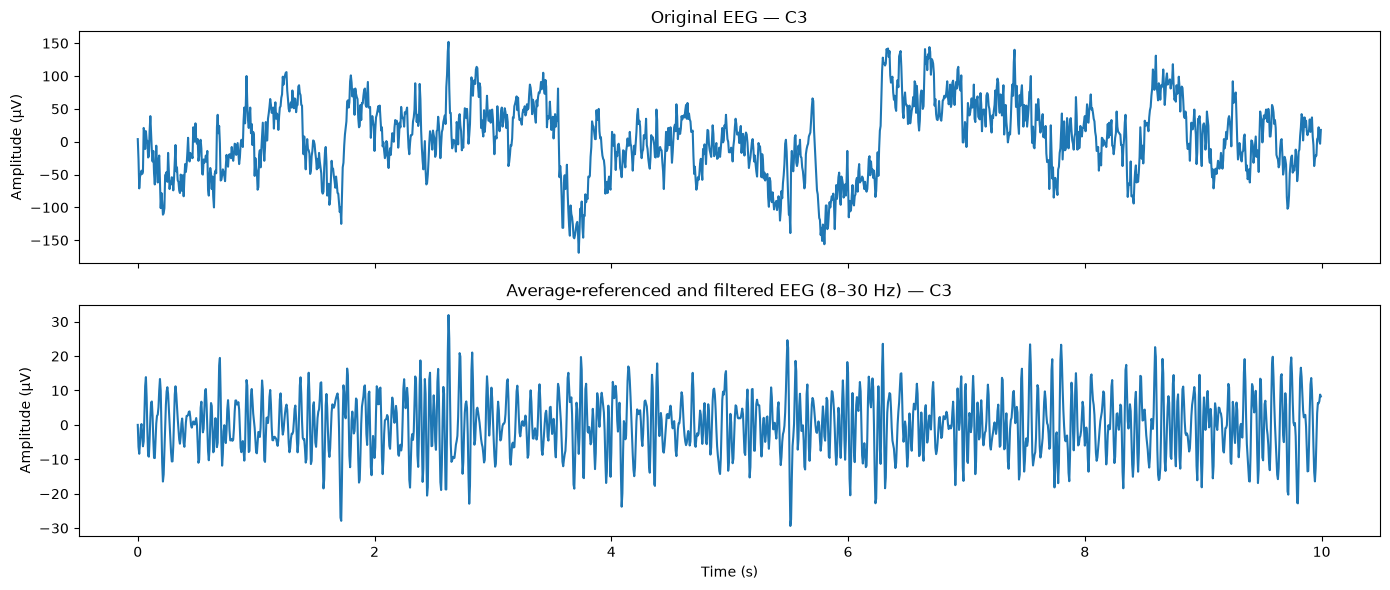

In [3]:
channel = "C3.."
start, stop = 0, 10

original_data = raw.get_data(picks=[channel], start=int(start * raw.info["sfreq"]), stop=int(stop * raw.info["sfreq"]))[0]
filtered_data = raw_processed.get_data(picks=[channel], start=int(start * raw.info["sfreq"]), stop=int(stop * raw.info["sfreq"]))[0]

times = np.arange(len(original_data)) / raw.info["sfreq"] + start
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(times, original_data * 1e6)
axes[0].set_title("Original EEG — C3")
axes[0].set_ylabel("Amplitude (µV)")

axes[1].plot(times, filtered_data * 1e6)
axes[1].set_title("Average-referenced and filtered EEG (8–30 Hz) — C3")
axes[1].set_ylabel("Amplitude (µV)")
axes[1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

### Observations

The preprocessed signal differs from the original EEG due to average referencing and 8–30 Hz band-pass filtering.

Low-frequency drift and components outside the selected frequency range are attenuated, while sensorimotor frequencies are retained.

Visual inspection illustrates the effect of preprocessing but does not confirm complete artifact removal.


## 4. Epoching:  Event Timing Analysis

Before epoch extraction, we examine the timing of EEG annotations and the intervals between consecutive events.

This helps verify whether the selected 4-second epoch window fits within each motor imagery trial without overlapping the next experimental condition.


In [4]:
events, event_id = mne.events_from_annotations(raw_processed, verbose=False)

# Map numeric event IDs to their annotation names
id_to_event = {value: name for name, value in event_id.items()}

# Create a table of event timestamps
events_df = pd.DataFrame({
    "sample": events[:, 0],
    "time_sec": events[:, 0] / raw_processed.info["sfreq"],
    "event": [id_to_event[event] for event in events[:, 2]]})

# Calculate the time until the next event
events_df["next_event_time_sec"] = events_df["time_sec"].shift(-1)
events_df["interval_to_next_sec"] = (
    events_df["next_event_time_sec"] - events_df["time_sec"])

print("Event timing:")
display(events_df.round(3))
print("\nIntervals between consecutive events:")
display(
    events_df.groupby("event")["interval_to_next_sec"]
    .agg(["count", "min", "median", "max"])
    .round(3))


Event timing:


,sample,time_sec,event,next_event_time_sec,interval_to_next_sec
0,0,0.0,T0,4.2,4.2
1,672,4.2,T2,8.3,4.1
2,1328,8.3,T0,12.5,4.2
3,2000,12.5,T1,16.6,4.1
4,2656,16.6,T0,20.8,4.2
5,3328,20.8,T1,24.9,4.1
6,3984,24.9,T0,29.1,4.2
7,4656,29.1,T2,33.2,4.1
8,5312,33.2,T0,37.4,4.2
9,5984,37.4,T2,41.5,4.1



Intervals between consecutive events:


,count,min,median,max
event,,,,
T0,15,4.2,4.2,4.2
T1,7,4.1,4.1,4.1
T2,7,4.1,4.1,4.1


### Observations

The intervals between consecutive events are 4.1–4.2 seconds, supporting the selection of a 4-second epoch window.

This window fits within the observed event intervals without reaching the next event onset.


## 5. Epoch Extraction

Four-second epochs are extracted from the preprocessed EEG, starting at each T0, T1, and T2 event.

Only channels C3, Cz, and C4 are retained for further analysis. Epoch counts are checked to verify the resulting dataset and class distribution.

In [5]:
selected_event_id = {
    name: event_id[name]
    for name in ["T0", "T1", "T2"]}

# Extract 4-second epochs from the preprocessed EEG
epochs = mne.Epochs(raw_processed, events, event_id=selected_event_id, tmin=0.0, tmax=4.0, picks=motor_channels, baseline=None, 
                    preload=True, reject_by_annotation=True, verbose=False)
print(epochs)
print("\nEpoch data shape:", epochs.get_data().shape)

print("\nEpoch counts by class:")
print(pd.Series(epochs.events[:, -1]).map(
    {value: key for key, value in selected_event_id.items()}
).value_counts().sort_index())


<Epochs | 30 events (all good), 0 – 4 s (baseline off), ~458 KiB, data loaded,
 'T0': 15
 'T1': 8
 'T2': 7>

Epoch data shape: (30, 3, 641)

Epoch counts by class:
T0    15
T1     8
T2     7
Name: count, dtype: int64


### Observations

All 30 annotated events were successfully converted into 4-second epochs using channels C3, Cz, and C4.

The resulting data shape is `(30, 3, 641)`, with 15 T0, 8 T1, and 7 T2 epochs. No epochs were dropped during extraction.

**Next step:** Assess epoch quality by examining maximum signal amplitudes and visually inspecting selected trials.

## 6. Epoch Quality Check

The maximum absolute amplitude is calculated for each epoch and selected channel to identify potentially unusual signal amplitudes.

These values are used for preliminary quality assessment, not as an automatic rejection criterion.

In [6]:
epochs_data = epochs.get_data()
max_amplitudes = np.max(np.abs(epochs_data), axis=2) * 1e6

amplitude_df = pd.DataFrame(
    max_amplitudes,
    columns=motor_channels)

amplitude_df.insert(0, "Event", [
    {value: key for key, value in selected_event_id.items()}[event]
    for event in epochs.events[:, -1]])

print("Maximum absolute amplitude per epoch and channel (µV):")
display(amplitude_df.round(2))

print("\nOverall amplitude summary (µV):")
display(amplitude_df[motor_channels].describe().round(2))

Maximum absolute amplitude per epoch and channel (µV):


,Event,C3..,Cz..,C4..
0,T0,31.93,29.70,30.60
1,T2,29.38,35.04,46.28
2,T0,28.55,27.22,27.14
3,T1,26.56,30.56,28.85
4,T0,31.13,23.41,34.20
5,T1,36.80,30.51,27.06
6,T0,43.68,26.91,33.54
7,T2,23.02,26.71,30.10
8,T0,31.79,43.44,46.56
9,T2,29.94,24.02,20.45



Overall amplitude summary (µV):


,C3..,Cz..,C4..
count,30.00,30.00,30.00
mean,35.06,30.25,32.99
std,6.97,5.24,7.06
min,23.02,23.15,20.45
25%,30.69,26.47,29.09
50%,33.56,30.15,31.74
75%,39.28,33.58,36.27
max,53.04,43.44,50.65


## 7. Visual Inspection of Epoch Quality

Four selected epochs are visualized across C3, Cz, and C4 to inspect signal morphology and identify potentially unusual patterns.

This is a qualitative check and does not establish the absence of artifacts across all epochs.

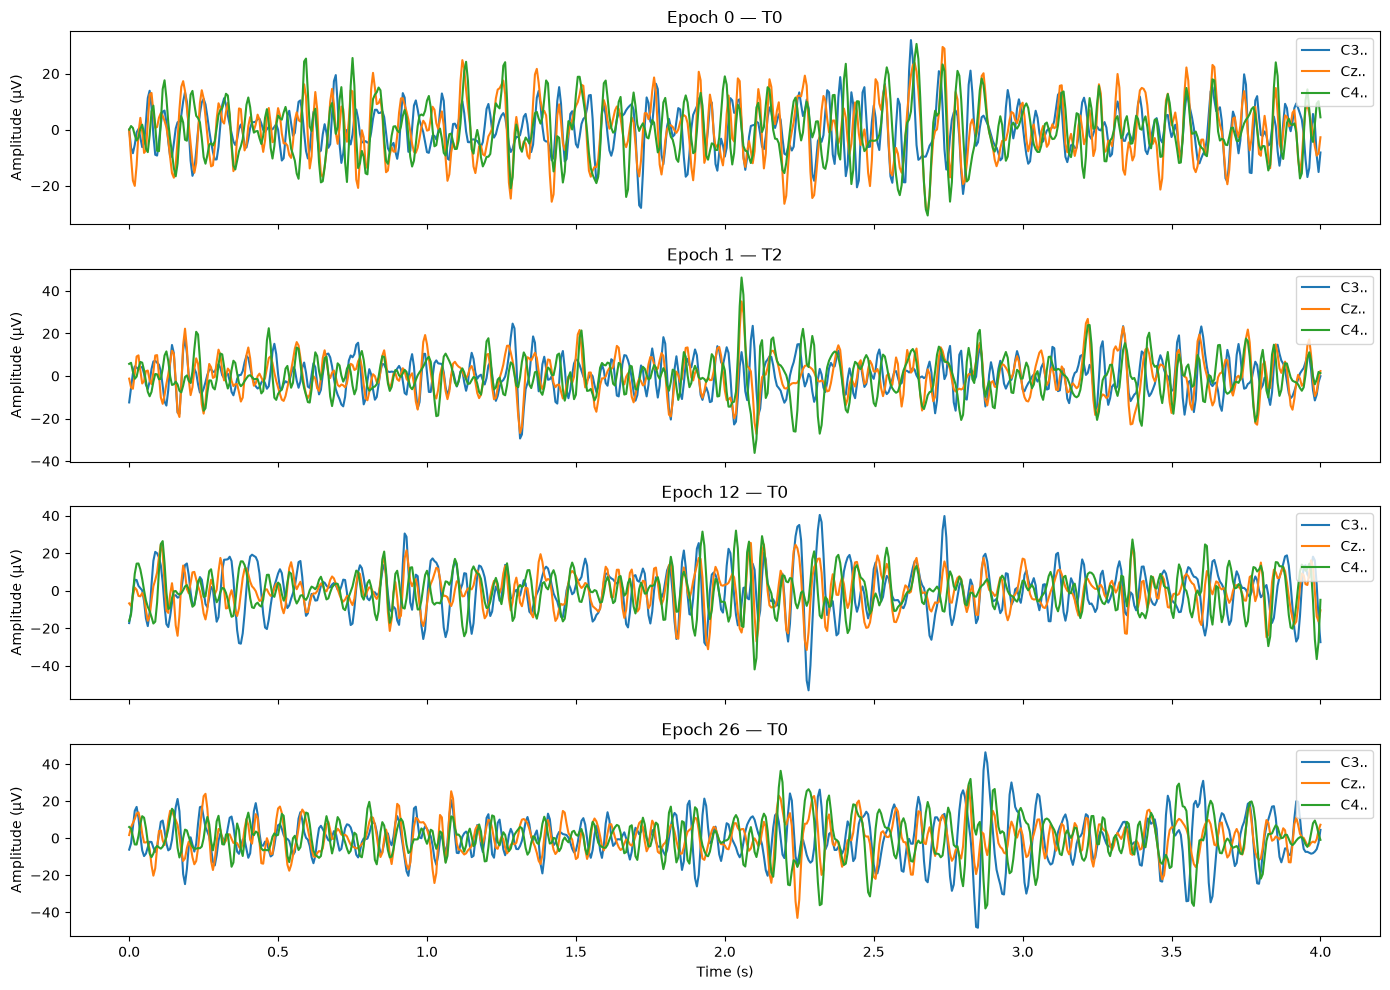

In [7]:
epochs_to_plot = [0, 1, 12, 26]
epochs_data = epochs.get_data()
times = epochs.times

fig, axes = plt.subplots(len(epochs_to_plot), 1, figsize=(14, 10), sharex=True)
for ax, epoch_idx in zip(axes, epochs_to_plot):
    for channel_idx, channel_name in enumerate(motor_channels):
        ax.plot(times, epochs_data[epoch_idx, channel_idx] * 1e6,label=channel_name)

    event_name = {value: key for key, value in selected_event_id.items()}[epochs.events[epoch_idx, -1]]

    ax.set_title(f"Epoch {epoch_idx} — {event_name}")
    ax.set_ylabel("Amplitude (µV)")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

### Observations

The selected epochs show EEG oscillations around zero, with occasional higher-amplitude deviations, particularly in epochs 1, 12, and 26.

No obvious prolonged signal disruptions are visible. However, potential artifacts cannot be ruled out based on visual inspection alone.

All 30 epochs are retained for further analysis.

## 8. Feature Extraction

Each EEG epoch is converted into a feature vector containing seven features per channel:

- **Time-domain:** mean, standard deviation, and root mean square (RMS).
- **Frequency-domain:** absolute and relative power in the mu/alpha (8–13 Hz) and beta (13–30 Hz) bands.

Features are calculated for C3, Cz, and C4, producing a structured dataset for subsequent analysis and classification.

In [8]:
from scipy.signal import welch

epochs_data = epochs.get_data()
sfreq = epochs.info["sfreq"]
feature_rows = []
for epoch_idx, epoch_data in enumerate(epochs_data):
    row = {}

    for channel_idx, channel_name in enumerate(motor_channels):
        signal = epoch_data[channel_idx]
        
        # Time-domain features
        row[f"{channel_name}_mean"] = np.mean(signal)
        row[f"{channel_name}_std"] = np.std(signal)
        row[f"{channel_name}_rms"] = np.sqrt(np.mean(signal ** 2))

        # Frequency-domain features
        freqs, psd = welch(signal, fs=sfreq, nperseg=256)

        alpha_mask = (freqs >= 8) & (freqs < 13)
        beta_mask = (freqs >= 13) & (freqs <= 30)

        df = freqs[1] - freqs[0]
        alpha_power = np.sum(psd[alpha_mask]) * df
        beta_power = np.sum(psd[beta_mask]) * df

        # Total power within the selected frequency bands
        total_power = alpha_power + beta_power

        row[f"{channel_name}_alpha_power"] = alpha_power
        row[f"{channel_name}_beta_power"] = beta_power

        # Relative band power
        if total_power > 0:
            row[f"{channel_name}_relative_alpha_power"] = alpha_power / total_power
            row[f"{channel_name}_relative_beta_power"] = beta_power / total_power
        else:
            row[f"{channel_name}_relative_alpha_power"] = np.nan
            row[f"{channel_name}_relative_beta_power"] = np.nan

    feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)
print("Feature matrix shape:", features_df.shape)
display(features_df.head().round(6))


Feature matrix shape: (30, 21)


,C3.._mean,C3.._std,C3.._rms,C3.._alpha_power,C3.._beta_power,C3.._relative_alpha_power,C3.._relative_beta_power,Cz.._mean,Cz.._std,Cz.._rms,...,Cz.._beta_power,Cz.._relative_alpha_power,Cz.._relative_beta_power,C4.._mean,C4.._std,C4.._rms,C4.._alpha_power,C4.._beta_power,C4.._relative_alpha_power,C4.._relative_beta_power
0,-0.0,0.000008,0.000008,0.0,0.0,0.240997,0.759003,-0.0,0.000010,0.000010,...,0.0,0.515077,0.484923,0.0,0.000010,0.000010,0.0,0.0,0.445018,0.554982
1,-0.0,0.000008,0.000008,0.0,0.0,0.286143,0.713857,0.0,0.000009,0.000009,...,0.0,0.560223,0.439777,0.0,0.000009,0.000009,0.0,0.0,0.451836,0.548164
2,0.0,0.000009,0.000009,0.0,0.0,0.340537,0.659463,-0.0,0.000008,0.000008,...,0.0,0.437529,0.562471,-0.0,0.000008,0.000008,0.0,0.0,0.377188,0.622812
3,-0.0,0.000008,0.000008,0.0,0.0,0.262062,0.737938,-0.0,0.000009,0.000009,...,0.0,0.463564,0.536436,-0.0,0.000009,0.000009,0.0,0.0,0.508946,0.491054
4,0.0,0.000010,0.000010,0.0,0.0,0.578841,0.421159,0.0,0.000008,0.000008,...,0.0,0.487786,0.512214,0.0,0.000010,0.000010,0.0,0.0,0.515486,0.484514


The feature matrix contains 30 epochs and 21 features: seven features for each of the three channels.

Absolute band power is expressed in V² and may appear as zero when rounded for display. The next step checks its numerical scale and verifies the relative power calculations.

### 9. Inspecting Extracted Band Power Features

Absolute band power is displayed in scientific notation to preserve its small numerical values. Relative band power is displayed separately to compare the proportions of alpha and beta power within the selected frequency range.


In [9]:
power_columns = [
    col for col in features_df.columns
    if ("alpha_power" in col or "beta_power" in col)
    and "relative_" not in col]

print("Absolute band power (scientific notation):")
display(features_df[power_columns].head().map(lambda x: f"{x:.3e}"))

print("\nRelative band power:")
relative_columns = [col for col in features_df.columns 
                    if "relative_" in col]
display(features_df[relative_columns].head().round(4))


Absolute band power (scientific notation):


,C3.._alpha_power,C3.._beta_power,Cz.._alpha_power,Cz.._beta_power,C4.._alpha_power,C4.._beta_power
0,1.500e-11,4.723e-11,4.383e-11,4.126e-11,3.812e-11,4.753e-11
1,1.613e-11,4.025e-11,3.600e-11,2.826e-11,3.589e-11,4.354e-11
2,2.104e-11,4.075e-11,2.358e-11,3.031e-11,2.080e-11,3.434e-11
3,1.534e-11,4.319e-11,2.790e-11,3.228e-11,3.488e-11,3.365e-11
4,4.859e-11,3.536e-11,3.309e-11,3.475e-11,5.022e-11,4.720e-11



Relative band power:


,C3.._relative_alpha_power,C3.._relative_beta_power,Cz.._relative_alpha_power,Cz.._relative_beta_power,C4.._relative_alpha_power,C4.._relative_beta_power
0,0.2410,0.7590,0.5151,0.4849,0.4450,0.5550
1,0.2861,0.7139,0.5602,0.4398,0.4518,0.5482
2,0.3405,0.6595,0.4375,0.5625,0.3772,0.6228
3,0.2621,0.7379,0.4636,0.5364,0.5089,0.4911
4,0.5788,0.4212,0.4878,0.5122,0.5155,0.4845


### 10. Feature Validation

In [10]:
print("Feature matrix shape:", features_df.shape)
print("Number of epochs:", len(features_df))
print("Number of features:", len(features_df.columns))

print("\nMissing values:", features_df.isna().sum().sum())
print("Duplicate rows:", features_df.duplicated().sum())
print("All values finite:", np.isfinite(features_df.to_numpy()).all())

print("\nFeature names:")
print(features_df.columns.tolist())

Feature matrix shape: (30, 21)
Number of epochs: 30
Number of features: 21

Missing values: 0
Duplicate rows: 0
All values finite: True

Feature names:
['C3.._mean', 'C3.._std', 'C3.._rms', 'C3.._alpha_power', 'C3.._beta_power', 'C3.._relative_alpha_power', 'C3.._relative_beta_power', 'Cz.._mean', 'Cz.._std', 'Cz.._rms', 'Cz.._alpha_power', 'Cz.._beta_power', 'Cz.._relative_alpha_power', 'Cz.._relative_beta_power', 'C4.._mean', 'C4.._std', 'C4.._rms', 'C4.._alpha_power', 'C4.._beta_power', 'C4.._relative_alpha_power', 'C4.._relative_beta_power']


In [11]:
absolute_power_columns = [col for col in features_df.columns 
                          if ("alpha_power" in col or "beta_power" in col) and "relative_" not in col]
print("All absolute powers are positive:",
      (features_df[absolute_power_columns] > 0).all().all())

print("\nAbsolute power ranges:")
display(features_df[absolute_power_columns].agg(["min", "max"]).T)


All absolute powers are positive: True

Absolute power ranges:


,min,max
C3.._alpha_power,1.172243e-11,1.097548e-10
C3.._beta_power,2.924160e-11,7.913455e-11
Cz.._alpha_power,1.242215e-11,5.468089e-11
Cz.._beta_power,2.826149e-11,5.772942e-11
C4.._alpha_power,1.361462e-11,6.073486e-11
C4.._beta_power,2.773275e-11,7.463313e-11


In [12]:
for channel in motor_channels:
    alpha = features_df[f"{channel}_relative_alpha_power"]
    beta = features_df[f"{channel}_relative_beta_power"]

    deviation = np.max(np.abs(alpha + beta - 1))

    print(f"{channel}: maximum deviation = {deviation:.2e}")

C3..: maximum deviation = 2.22e-16
Cz..: maximum deviation = 2.22e-16
C4..: maximum deviation = 2.22e-16



## Preliminary Conclusion

The preprocessing and feature extraction pipeline produced a feature matrix with 30 epochs and 21 features.

The extracted features summarize amplitude statistics and spectral power across C3, Cz, and C4. Relative alpha and beta power sum to approximately 1 for each channel and epoch because they are normalized by their combined power within the selected 8–30 Hz range.

The dataset contains 30 epochs from a single recording, with an imbalanced event distribution: T0 (15), T1 (8), and T2 (7). These features are intended for exploratory analysis and subsequent classification experiments; their discriminative value has not yet been established.


In [13]:
# eeg_features.csv — one record, S001R04, 30 epochs.
id_to_event = {value: name for name, value in selected_event_id.items()}
y = pd.Series(
    [id_to_event[event] for event in epochs.events[:, -1]],
    name="event")

dataset_df = features_df.copy()
dataset_df["event"] = y.to_numpy()

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "eeg_features.csv"
dataset_df.to_csv(output_path, index=False)

print(f"Dataset saved to: {output_path}")
print("Dataset shape:", dataset_df.shape)
print("\nEvent distribution:")
print(dataset_df["event"].value_counts())

Dataset saved to: ../data/processed/eeg_features.csv
Dataset shape: (30, 22)

Event distribution:
event
T0    15
T1     8
T2     7
Name: count, dtype: int64


### 11. Feature Extraction Across Multiple Subjects

The validated preprocessing and feature extraction pipeline is applied to 15 motor imagery recordings from five subjects (runs R04, R08, and R12).

Each epoch is represented by 21 features extracted from C3, Cz, and C4. Subject IDs, recording IDs, and event labels are preserved for subsequent model training and subject-independent evaluation.

The combined dataset is saved as `eeg_features_all_subjects.csv`.

In [14]:
def preprocess_eeg(raw_path):
    raw = mne.io.read_raw_edf(raw_path, preload=True, verbose=False)
    raw_processed = raw.copy()

    raw_processed.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
    raw_processed.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

    return raw_processed

In [15]:
def extract_eeg_features(raw_processed):
    motor_channels = ["C3..", "Cz..", "C4.."]
    # Extract events and validate required classes
    events, event_id = mne.events_from_annotations(raw_processed, verbose=False)
    required_events = ["T0", "T1", "T2"]
    missing_events = set(required_events) - set(event_id)

    if missing_events:
        raise ValueError(f"Missing event annotations: {missing_events}")

    selected_event_id = {name: event_id[name] for name in required_events}

    # Extract 4-second epochs
    epochs = mne.Epochs(raw_processed, events, event_id=selected_event_id, tmin=0.0, tmax=4.0, picks=motor_channels,
                        baseline=None, preload=True, reject_by_annotation=True, verbose=False)

    if len(epochs) == 0:
        raise ValueError("No valid epochs were extracted.")

    epochs_data = epochs.get_data()
    sfreq = epochs.info["sfreq"]

    id_to_event = {value: name for name, value in selected_event_id.items()}
    feature_rows = []

    # Extract features for each epoch and channel
    for epoch_idx, epoch_data in enumerate(epochs_data):
        row = {}
        for channel_idx, channel_name in enumerate(motor_channels):
            signal = epoch_data[channel_idx]

            # Time-domain features
            row[f"{channel_name}_mean"] = np.mean(signal)
            row[f"{channel_name}_std"] = np.std(signal)
            row[f"{channel_name}_rms"] = np.sqrt(np.mean(signal ** 2))

            # Frequency-domain features
            freqs, psd = welch(signal, fs=sfreq, nperseg=256)
            alpha_mask = (freqs >= 8) & (freqs < 13)
            beta_mask = (freqs >= 13) & (freqs <= 30)
            df = freqs[1] - freqs[0]

            # Absolute band power
            alpha_power = np.sum(psd[alpha_mask]) * df
            beta_power = np.sum(psd[beta_mask]) * df

            row[f"{channel_name}_alpha_power"] = alpha_power
            row[f"{channel_name}_beta_power"] = beta_power

            # Relative band power
            total_power = alpha_power + beta_power

            if total_power > 0:
                row[f"{channel_name}_relative_alpha_power"] = alpha_power / total_power
                row[f"{channel_name}_relative_beta_power"] = beta_power / total_power
            else:
                row[f"{channel_name}_relative_alpha_power"] = np.nan
                row[f"{channel_name}_relative_beta_power"] = np.nan

        # Add event label
        row["event"] = id_to_event[epochs.events[epoch_idx, -1]]
        feature_rows.append(row)

    features_df = pd.DataFrame(feature_rows)

    return features_df, epochs

### Conclusion

The pipeline successfully processed 15 EEG recordings from five subjects, producing 450 epochs and 21 numerical features per epoch.

The dataset contains 225 T0, 113 T1, and 112 T2 epochs. The T1 and T2 classes are nearly balanced, providing 225 motor imagery epochs for binary classification.

Subject and recording identifiers are retained to support leakage-aware, subject-independent model evaluation.

**Next step:** Explore class-specific feature distributions and evaluate baseline classifiers.

### 12. Processing Multiple EEG Recordings

The preprocessing and feature extraction functions are applied to 15 motor imagery recordings from five subjects.

Subject and recording identifiers are added to each epoch to support subject-independent model evaluation.

In [16]:
raw_dir = Path("../data/raw")
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)
subject_ids = [f"S{i:03d}" for i in range(1, 6)]
run_ids = ["R04", "R08", "R12"]

edf_files = [raw_dir / f"{subject}{run}.edf" for subject in subject_ids for run in run_ids]
missing_files = [path for path in edf_files if not path.is_file()]

if missing_files:
    raise FileNotFoundError(f"Missing EDF files: {missing_files}")
print(f"EDF files found: {len(edf_files)}")

quality_records = []
all_features = []
for i, raw_path in enumerate(edf_files, start=1):
    # Extract subject and recording IDs from filename
    subject_id = raw_path.stem[:4]
    recording_id = raw_path.stem
    print(f"[{i}/{len(edf_files)}] Processing {recording_id}...")

    # Preprocess EEG
    raw_processed = preprocess_eeg(raw_path)

    # Extract features
    features_df, epochs = extract_eeg_features(raw_processed)
    
    # Maximum absolute amplitude across channels and time (µV)
    peak_amplitudes = np.max(np.abs(epochs.get_data()), axis=(1, 2)) * 1e6
    id_to_event = {value: name for name, value in epochs.event_id.items()}

    for epoch_idx, peak_amplitude in enumerate(peak_amplitudes):
        quality_records.append({"subject_id": subject_id,
                                "recording_id": recording_id,
                                "event": id_to_event[epochs.events[epoch_idx, -1]],
                                "peak_amplitude_uv": peak_amplitude})

    # Add metadata
    features_df.insert(0, "recording_id", recording_id)
    features_df.insert(0, "subject_id", subject_id)

    all_features.append(features_df)

    # Release memory before processing the next recording
    del raw_processed, features_df, epochs

# Combine all recordings
all_features_df = pd.concat(all_features, ignore_index=True)

# Save the combined dataset
output_path = output_dir / "eeg_features_all_subjects.csv"
all_features_df.to_csv(output_path, index=False)

print("\nDataset saved to:", output_path)
print("Dataset shape:", all_features_df.shape)

print("\nRecordings per subject:")
print(all_features_df.groupby("subject_id")["recording_id"].nunique())

print("\nEvents per subject:")
print(pd.crosstab(all_features_df["subject_id"], all_features_df["event"]))

print("\nTotal event distribution:")
print(all_features_df["event"].value_counts())

EDF files found: 15
[1/15] Processing S001R04...
[2/15] Processing S001R08...
[3/15] Processing S001R12...
[4/15] Processing S002R04...
[5/15] Processing S002R08...
[6/15] Processing S002R12...
[7/15] Processing S003R04...
[8/15] Processing S003R08...
[9/15] Processing S003R12...
[10/15] Processing S004R04...
[11/15] Processing S004R08...
[12/15] Processing S004R12...
[13/15] Processing S005R04...
[14/15] Processing S005R08...
[15/15] Processing S005R12...

Dataset saved to: ../data/processed/eeg_features_all_subjects.csv
Dataset shape: (450, 24)

Recordings per subject:
subject_id
S001    3
S002    3
S003    3
S004    3
S005    3
Name: recording_id, dtype: int64

Events per subject:
event       T0  T1  T2
subject_id            
S001        45  23  22
S002        45  23  22
S003        45  23  22
S004        45  23  22
S005        45  21  24

Total event distribution:
event
T0    225
T1    113
T2    112
Name: count, dtype: int64


### 13. Epoch Quality Assessment Across Subjects

We examine maximum absolute EEG amplitudes across all recordings to identify potentially unusual epochs.

A provisional 100 µV threshold is used to flag epochs for further inspection, without automatically excluding them from the dataset.

In [17]:
quality_df = pd.DataFrame(quality_records)

threshold_uv = 100
quality_df["flagged"] = quality_df["peak_amplitude_uv"] > threshold_uv

quality_summary = quality_df.groupby("subject_id").agg(Epochs=("flagged", "size"),
                                                       Flagged=("flagged", "sum"),
                                                       Median_peak_uv=("peak_amplitude_uv", "median"),
                                                       Max_peak_uv=("peak_amplitude_uv", "max"))

quality_summary["Flagged_pct"] = (quality_summary["Flagged"] / quality_summary["Epochs"] * 100)

display(quality_summary.round(2))

print("Total flagged epochs:", quality_df["flagged"].sum())
print("Total epochs:", len(quality_df))

,Epochs,Flagged,Median_peak_uv,Max_peak_uv,Flagged_pct
subject_id,,,,,
S001,90,0,36.36,53.04,0.00
S002,90,0,32.95,86.59,0.00
S003,90,1,32.71,102.58,1.11
S004,90,0,17.01,44.22,0.00
S005,90,0,18.16,39.71,0.00


Total flagged epochs: 1
Total epochs: 450


### Epoch Quality Results

Only 1 of 450 epochs (0.22%) exceeded the provisional 100 µV amplitude threshold.

The flagged epoch belongs to S003 and has a maximum absolute amplitude of 102.58 µV.

No epochs were automatically excluded, as threshold exceedance alone does not confirm an artifact.

In [19]:
flagged_epochs = quality_df.loc[quality_df["flagged"],
    ["subject_id", "recording_id", "event", "peak_amplitude_uv"]]

display(flagged_epochs)

,subject_id,recording_id,event,peak_amplitude_uv
204,S003,S003R04,T0,102.577994


### Quality Assessment Conclusion

The only epoch exceeding the provisional 100 µV threshold belongs to the resting-state class (T0) in recording S003R04.

None of the 225 motor imagery epochs (T1/T2) exceeded this threshold.

No epochs were removed. The original dataset was retained for model training, although other types of artifacts cannot be ruled out by amplitude screening alone.

### 14. Dataset Validation

The combined dataset is checked for missing values, non-finite features, and duplicate rows. We also verify the expected number of features, subjects, and recordings before model training.

In [20]:
feature_columns = [col for col in all_features_df.columns
    if col not in ["subject_id", "recording_id", "event"]]

print("Number of features:", len(feature_columns))
print("Missing values:", all_features_df.isna().sum().sum())
print("Duplicate rows:", all_features_df.duplicated().sum())
print("All features finite:", np.isfinite(all_features_df[feature_columns].to_numpy()).all())

print("\nDataset structure:")
print("Subjects:", all_features_df["subject_id"].nunique())
print("Recordings:", all_features_df["recording_id"].nunique())
print("Epochs:", len(all_features_df))

assert len(feature_columns) == 21
assert all_features_df.isna().sum().sum() == 0
assert np.isfinite(all_features_df[feature_columns].to_numpy()).all()
assert all_features_df["subject_id"].nunique() == 5
assert all_features_df["recording_id"].nunique() == 15
assert len(all_features_df) == 450

Number of features: 21
Missing values: 0
Duplicate rows: 0
All features finite: True

Dataset structure:
Subjects: 5
Recordings: 15
Epochs: 450


## Conclusion

EEG recordings from five subjects were preprocessed and segmented into 450 epochs, including 225 motor imagery epochs (T1/T2).

A total of 21 time- and frequency-domain features were extracted from C3, Cz, and C4.

Quality assessment identified one epoch exceeding the provisional 100 µV threshold, belonging to the resting-state class (T0). No motor imagery epochs exceeded this threshold.

Dataset validation confirmed no missing values, non-finite features, or duplicate rows.

**Next step:** Train and evaluate baseline classifiers using subject-aware cross-validation.